# Classical segmentation of AF488 against Cellpose + a positivity rule

The cells analysis calls a cell AF488-positive in two steps: **Cellpose finds every nucleus** (on the nuclear stain), then each cell's AF488 is compared with a threshold — **median + 3 SD** of the region's cells (the default) or **ring contrast ≥ 1.5** (the cell over a ring 3–6 µm round its nucleus). The positive cell is therefore always *a nucleus grown by 3 µm*: whatever shape the labelled cell has, its outline is a blob.

The alternative asked here: **segment the AF488 signal itself** with a classical threshold, as Fiji or CellProfiler would. Two questions:

1. **Does it find the same positive cells?** Per sample (counts) and per cell (is a Cellpose cell that a rule calls positive covered by the AF488 mask, and the other way round?).
2. **Does it give more of the cell's structure** — cytoplasm, processes — than the nucleus-based outline?

**The classical pipeline** (`classical_vs_cellpose.py`, per sample, at full resolution, 0.325 µm a pixel):

- AF488 flattened over Z, smoothed (Gaussian, 0.5 µm);
- its **local background taken away** (Gaussian of 20 µm, computed at 1/4 resolution) — what a rolling ball does, so a bright region of tissue does not light up as a whole;
- thresholded **inside the tissue** (the nuclear stain's outline), three kinds of rule: **k × robust SD** of the background-subtracted tissue for k = 3, 5, 8 (`kmad3`, `kmad5`, `kmad8`), **triangle** (built for a histogram with one big peak and a long tail, which is what AF488 has) and **Otsu** (the classic two-group split);
- objects under 20 µm² dropped, holes under 10 µm² filled.

**The comparison.** The Cellpose cells, nuclei and grown regions are the ones the cells analysis saved (the newest run of each sample); nothing is segmented again. A Cellpose cell is *covered* by a classical mask when the mask covers at least 25 % of its grown region (other shares are tried in section 2). Agreement is measured with **Cohen's κ** (0 = chance, 1 = identical calls).

Everything is computed by the script into `junction_eval/classical/` (≈15 s a sample, CPU only); this notebook only reads it.

In [1]:
from pathlib import Path
import json
import ssl
import sys
import warnings

try:
    ssl.create_default_context()
except ssl.SSLError:
    ssl.SSLContext._load_windows_store_certs = lambda self, storename, purpose: None

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "microscopy_viewer").is_dir())
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(Path.cwd()))
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

import classical_vs_cellpose as CV

RULES = ("median + 3 SD", "ring ≥ 1.5")
METHODS = CV.METHODS
MAIN = "kmad5"
NAMES = sorted(p.name for p in CV.OUT.iterdir() if (p / "summary.json").is_file())
SUMMARY = {n: json.loads((CV.OUT / n / "summary.json").read_text(encoding="utf-8")) for n in NAMES}
CELLS = {n: pd.read_parquet(CV.OUT / n / "cells.parquet") for n in NAMES}
OBJECTS = {(n, m): pd.read_parquet(CV.OUT / n / f"objects_{m}.parquet") for n in NAMES for m in METHODS}
for n in NAMES:
    for m in METHODS:
        CELLS[n][f"covered {m}"] = CELLS[n][f"cover {m}"].fillna(0) >= CV.COVER
print(f"{len(NAMES)} samples, {sum(len(c) for c in CELLS.values()):,} Cellpose cells; methods {METHODS}")

39 samples, 1,733,165 Cellpose cells; methods ('kmad3', 'kmad5', 'kmad8', 'triangle', 'otsu')


## 1. Counts per sample

Per sample: the cells each Cellpose rule calls positive, and the Cellpose cells each classical mask covers, in the whole section and in the junction region; and how many separate objects each classical mask has.

**How to read it.** If the classical masks found the same positive cells, the covered counts would track the rule's counts across samples (high Spearman ρ) at a similar level. The thresholds are in the image's own units after the background is taken away; *noise SD* is the robust spread of the background-subtracted tissue.

In [2]:
rows = []
for n in NAMES:
    c, s = CELLS[n], SUMMARY[n]
    region = c["In region"].astype(bool)
    row = {"sample": n.replace("2025_09_26_Asssembloid_", ""), "cells": len(c), "noise SD": round(s["noise_sd"], 1)}
    for r in RULES:
        row[f"{r}"] = int(c[r].sum())
        row[f"{r} (region)"] = int((c[r] & region).sum())
    for m in METHODS:
        row[f"{m} cells"] = int(c[f"covered {m}"].sum())
        row[f"{m} cells (region)"] = int((c[f"covered {m}"] & region).sum())
        row[f"{m} objects"] = len(OBJECTS[(n, m)])
    rows.append(row)
COUNTS = pd.DataFrame(rows).set_index("sample")
display(COUNTS[["cells", *RULES, *(f"{m} cells" for m in METHODS), *(f"{m} objects" for m in METHODS)]])

def rho(a, b):
    return stats.spearmanr(COUNTS[a], COUNTS[b]).correlation

table = pd.DataFrame({
    f"{m}": {**{f"ρ vs {r}": rho(f"{m} cells", r) for r in RULES},
             **{f"ρ vs {r} (region)": rho(f"{m} cells (region)", f"{r} (region)") for r in RULES},
             "median cells / median + 3 SD": float(np.median(COUNTS[f"{m} cells"] / COUNTS["median + 3 SD"].clip(lower=1))),
             "median cells / ring ≥ 1.5": float(np.median(COUNTS[f"{m} cells"] / COUNTS["ring ≥ 1.5"].clip(lower=1)))}
    for m in METHODS}).T
table.loc["ring ≥ 1.5 (Cellpose)"] = {f"ρ vs median + 3 SD": rho("ring ≥ 1.5", "median + 3 SD"),
                                     "ρ vs median + 3 SD (region)": rho("ring ≥ 1.5 (region)", "median + 3 SD (region)")}
display(table.round(2))

,cells,median + 3 SD,ring ≥ 1.5,kmad3 cells,kmad5 cells,kmad8 cells,triangle cells,otsu cells,kmad3 objects,kmad5 objects,kmad8 objects,triangle objects,otsu objects
sample,,,,,,,,,,,,,
018-017_s1,29590,1186,182,1130,568,315,230,3,632,330,192,147,3
018-017_s10,44201,3485,230,1664,665,305,302,6,798,363,166,161,7
018-017_s11,37445,3529,174,1322,507,220,230,1,672,301,156,166,2
018-017_s13,48036,1425,275,1856,767,316,799,203,850,390,191,403,134
018-017_s2,25033,865,112,1050,502,236,436,27,532,294,169,265,24
018-017_s3,21131,1796,124,817,383,220,351,39,436,224,138,218,32
018-017_s4,29771,1379,192,1109,541,278,290,1,569,326,188,196,1
018-017_s5,31218,2574,310,1346,618,279,481,34,648,384,202,326,35
018-017_s6,25476,2317,164,950,415,191,397,80,510,270,142,263,79


,ρ vs median + 3 SD,ρ vs ring ≥ 1.5,ρ vs median + 3 SD (region),ρ vs ring ≥ 1.5 (region),median cells / median + 3 SD,median cells / ring ≥ 1.5
kmad3,0.26,0.77,0.67,0.68,0.80,5.83
kmad5,0.21,0.79,0.52,0.72,0.31,2.38
kmad8,0.12,0.73,0.38,0.63,0.14,1.08
triangle,-0.10,0.51,0.41,0.74,0.20,1.32
otsu,-0.36,0.27,0.23,0.44,0.01,0.12
ring ≥ 1.5 (Cellpose),0.20,NaN,0.47,NaN,NaN,NaN


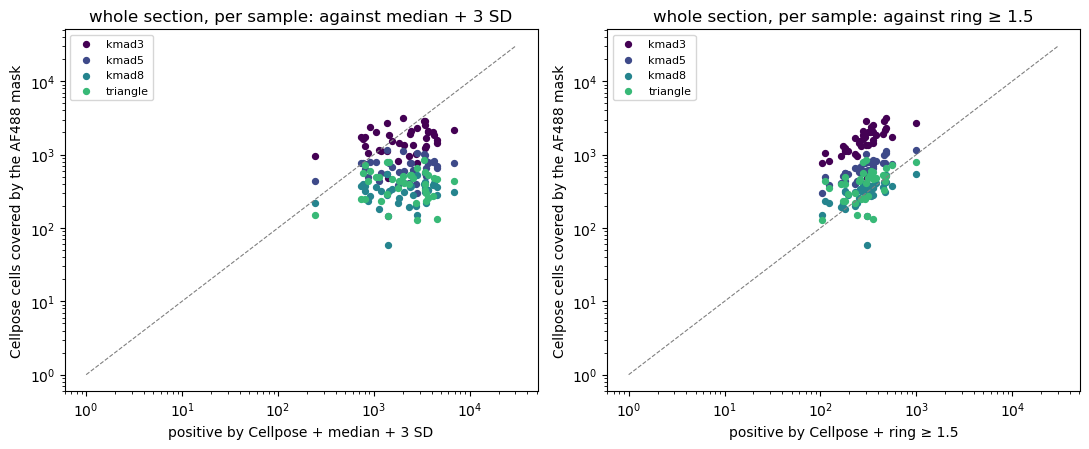

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, rule in zip(axes, RULES):
    for m, colour in zip(METHODS, plt.cm.viridis(np.linspace(0, 0.9, len(METHODS)))):
        if m == "otsu":
            continue
        ax.scatter(COUNTS[rule].clip(lower=1), COUNTS[f"{m} cells"].clip(lower=1), s=18, color=colour, label=m)
    lim = [1, max(COUNTS[[rule, *(f"{m} cells" for m in METHODS)]].max()) * 1.5]
    ax.plot(lim, lim, color="grey", lw=0.8, ls="--")
    ax.set(xscale="log", yscale="log", xlabel=f"positive by Cellpose + {rule}", ylabel="Cellpose cells covered by the AF488 mask",
           title=f"whole section, per sample: against {rule}")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 2. Cell by cell

Pooled over every sample: for each Cellpose rule and each classical mask, how many cells each calls positive, how many both do, the share of the rule's positives the mask covers (*rule's found by mask*), the share of covered cells the rule calls positive (*mask's called by rule*), and Cohen's κ. The last column is κ's median over samples, so one large sample does not decide it.

In [4]:
def kappa(a, b):
    a, b = np.asarray(a, bool), np.asarray(b, bool)
    po = np.mean(a == b)
    pe = a.mean() * b.mean() + (1 - a.mean()) * (1 - b.mean())
    return (po - pe) / (1 - pe) if pe < 1 else np.nan

ALL = pd.concat([CELLS[n].assign(sample=n) for n in NAMES], ignore_index=True)
rows = []
for r in RULES:
    for m in METHODS:
        a, b = ALL[r].to_numpy(bool), ALL[f"covered {m}"].to_numpy(bool)
        rows.append({"rule": r, "mask": m, "rule +": int(a.sum()), "mask covers": int(b.sum()), "both": int((a & b).sum()),
                     "rule's found by mask": (a & b).sum() / max(a.sum(), 1), "mask's called by rule": (a & b).sum() / max(b.sum(), 1),
                     "κ pooled": kappa(a, b),
                     "κ median per sample": np.nanmedian([kappa(CELLS[n][r], CELLS[n][f"covered {m}"]) for n in NAMES])})
a, b = ALL["median + 3 SD"].to_numpy(bool), ALL["ring ≥ 1.5"].to_numpy(bool)
rows.append({"rule": "median + 3 SD", "mask": "(ring ≥ 1.5)", "rule +": int(a.sum()), "mask covers": int(b.sum()), "both": int((a & b).sum()),
             "rule's found by mask": (a & b).sum() / max(a.sum(), 1), "mask's called by rule": (a & b).sum() / max(b.sum(), 1),
             "κ pooled": kappa(a, b), "κ median per sample": np.nanmedian([kappa(CELLS[n]["median + 3 SD"], CELLS[n]["ring ≥ 1.5"]) for n in NAMES])})
AGREE = pd.DataFrame(rows)
display(AGREE.round(3))

,rule,mask,rule +,mask covers,both,rule's found by mask,mask's called by rule,κ pooled,κ median per sample
0,median + 3 SD,kmad3,93888,65639,31996,0.341,0.487,0.373,0.373
1,median + 3 SD,kmad5,93888,26638,18797,0.200,0.706,0.295,0.292
2,median + 3 SD,kmad8,93888,12260,10994,0.117,0.897,0.197,0.201
3,median + 3 SD,triangle,93888,16539,13103,0.140,0.792,0.225,0.263
4,median + 3 SD,otsu,93888,25726,4318,0.046,0.168,0.050,0.026
5,ring ≥ 1.5,kmad3,12259,65639,9345,0.762,0.142,0.231,0.230
6,ring ≥ 1.5,kmad5,12259,26638,8047,0.656,0.302,0.408,0.407
7,ring ≥ 1.5,kmad8,12259,12260,6161,0.503,0.503,0.499,0.534
8,ring ≥ 1.5,triangle,12259,16539,6757,0.551,0.409,0.465,0.496
9,ring ≥ 1.5,otsu,12259,25726,2452,0.200,0.095,0.121,0.133


**How much the 25 % coverage matters.** The same comparison for the main mask (`kmad5`) with a cell counted as covered from 5 % to 90 % of its grown region on.

In [5]:
shares = (0.05, 0.1, 0.25, 0.5, 0.75, 0.9)
rows = []
for share in shares:
    covered = ALL[f"cover {MAIN}"].fillna(0).to_numpy() >= share
    rows.append({"covered from": share, "cells covered": int(covered.sum()),
                 **{f"κ vs {r}": kappa(ALL[r], covered) for r in RULES},
                 **{f"{r}'s found": (ALL[r].to_numpy(bool) & covered).sum() / max(ALL[r].sum(), 1) for r in RULES}})
display(pd.DataFrame(rows).round(3))

,covered from,cells covered,κ vs median + 3 SD,κ vs ring ≥ 1.5,median + 3 SD's found,ring ≥ 1.5's found
0,0.05,53103,0.327,0.258,0.276,0.710
1,0.10,44088,0.328,0.296,0.258,0.699
2,0.25,26638,0.295,0.408,0.200,0.656
3,0.50,11680,0.185,0.493,0.110,0.484
4,0.75,4633,0.086,0.361,0.047,0.250
5,0.90,2128,0.041,0.213,0.022,0.126


## 3. Do they tell the same story about where the positive cells are?

The share of cells positive against their distance to the junction line (negative: across the line from the band's side), pooled over every sample, for each Cellpose rule and for the cells the classical masks cover. What matters downstream is the shape of these curves — a step at the line, a tail into the other organoid — more than their height.

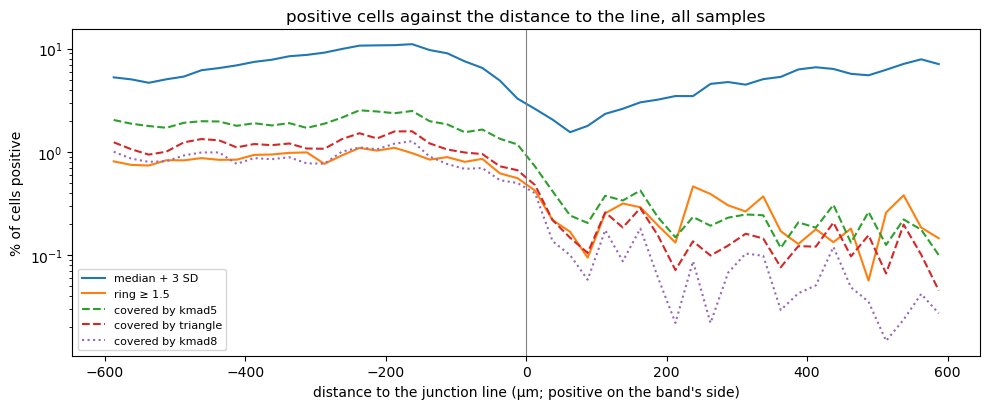

In [6]:
edges = np.arange(-600, 601, 25.0)
mid = (edges[:-1] + edges[1:]) / 2
d = ALL["Distance to the junction line (µm)"].to_numpy(float)
fig, ax = plt.subplots(figsize=(10, 4.2))
for label, column, style in [("median + 3 SD", "median + 3 SD", "-"), ("ring ≥ 1.5", "ring ≥ 1.5", "-"),
                             (f"covered by {MAIN}", f"covered {MAIN}", "--"), ("covered by triangle", "covered triangle", "--"),
                             ("covered by kmad8", "covered kmad8", ":")]:
    v = ALL[column].to_numpy(bool)
    share = [100 * v[(d >= a) & (d < b)].mean() if ((d >= a) & (d < b)).sum() > 200 else np.nan for a, b in zip(edges[:-1], edges[1:])]
    ax.plot(mid, share, style, label=label)
ax.axvline(0, color="grey", lw=0.8)
ax.set(xlabel="distance to the junction line (µm; positive on the band's side)", ylabel="% of cells positive", yscale="log",
       title="positive cells against the distance to the line, all samples")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 4. Shape: does thresholding the label give more of the cell?

Per classical mask, pooled over samples: the objects it finds, their size, their **skeleton length** (the length of the object's centre line — long for a cell with processes, short for a round blob), their **solidity** (area over convex hull: 1 for a convex blob, low for a branched or ragged shape), how many Cellpose nuclei each touches (0: signal with no nucleus under it — a process, a fragment or debris; 2 or more: neighbouring cells merged into one object), and how much of the mask lies **outside every nucleus** and **outside every grown region** (nucleus + 3 µm, the area the rules measure over).

For comparison, a Cellpose positive cell's outline is its nucleus grown by 3 µm: the last row gives the median nucleus area of the cells median + 3 SD calls positive.

**Two of these numbers mislead on their own.** The image is flattened over Z (maximum of the planes), so a labelled cell or process lying above or below unlabelled nuclei *touches* them in 2D: "nuclei touched" counts overlaps in the flattened image, not cells merged. And in dense tissue the grown regions (every nucleus + 3 µm, split between neighbours) tile almost all of it, so "outside grown regions" is near zero whatever the mask's shape. The share **outside nuclei** and the **skeleton length** are the ones that say whether the mask holds more than the nucleus; the pictures in section 5 say it best.

In [7]:
rows = []
for m in METHODS:
    o = pd.concat([OBJECTS[(n, m)] for n in NAMES if len(OBJECTS[(n, m)])], ignore_index=True)
    areas = {k: sum(SUMMARY[n]["mask_areas"][m][k] for n in NAMES) for k in ("mask_area_um2", "outside_nuclei_um2", "outside_cells_um2")}
    rows.append({"mask": m, "objects": len(o), "median area (µm²)": o["Area (µm²)"].median(), "P90 area (µm²)": o["Area (µm²)"].quantile(0.9),
                 "median skeleton (µm)": o["Skeleton (µm)"].median(), "P90 skeleton (µm)": o["Skeleton (µm)"].quantile(0.9),
                 "median solidity": o["Solidity"].median(),
                 "% touching 0 nuclei": 100 * (o["Nuclei touched"] == 0).mean(), "% touching 1": 100 * (o["Nuclei touched"] == 1).mean(),
                 "% touching ≥ 2": 100 * (o["Nuclei touched"] >= 2).mean(),
                 "% of mask outside nuclei": 100 * areas["outside_nuclei_um2"] / max(areas["mask_area_um2"], 1),
                 "% of mask outside grown regions": 100 * areas["outside_cells_um2"] / max(areas["mask_area_um2"], 1)})
SHAPE = pd.DataFrame(rows).set_index("mask")
display(SHAPE.round(1))
pos = ALL[ALL["median + 3 SD"]]
print(f"Cellpose, median + 3 SD positives: median nucleus area {pos['Nucleus area (µm²)'].median():.0f} µm² "
      f"(grown by 3 µm ≈ {np.pi * (np.sqrt(pos['Nucleus area (µm²)'].median() / np.pi) + 3) ** 2:.0f} µm²)")

,objects,median area (µm²),P90 area (µm²),median skeleton (µm),P90 skeleton (µm),median solidity,% touching 0 nuclei,% touching 1,% touching ≥ 2,% of mask outside nuclei,% of mask outside grown regions
mask,,,,,,,,,,,
kmad3,31149,50.0,176.8,10.1,32.5,0.9,8.0,17.3,74.7,62.2,9.0
kmad5,16049,45.7,139.7,8.1,23.4,0.9,9.0,19.4,71.6,60.4,9.8
kmad8,8434,42.8,119.9,7.2,19.5,0.9,9.3,21.9,68.8,58.6,10.4
triangle,10847,43.9,128.3,7.5,21.1,0.9,9.7,21.1,69.2,59.1,9.0
otsu,7036,50.9,233.9,11.0,50.9,0.8,8.2,15.6,76.2,59.7,9.0


Cellpose, median + 3 SD positives: median nucleus area 20 µm² (grown by 3 µm ≈ 97 µm²)


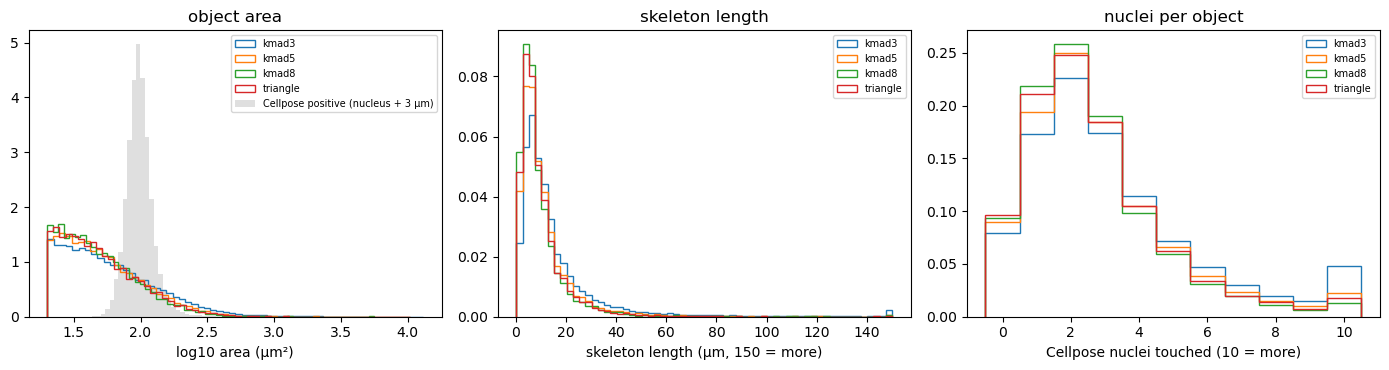

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for m in ("kmad3", MAIN, "kmad8", "triangle"):
    o = pd.concat([OBJECTS[(n, m)] for n in NAMES], ignore_index=True)
    axes[0].hist(np.log10(o["Area (µm²)"]), bins=60, histtype="step", density=True, label=m)
    axes[1].hist(o["Skeleton (µm)"].clip(upper=150), bins=60, histtype="step", density=True, label=m)
    axes[2].hist(o["Nuclei touched"].clip(upper=10), bins=np.arange(12) - 0.5, histtype="step", density=True, label=m)
grown = np.log10(np.pi * (np.sqrt(pos["Nucleus area (µm²)"] / np.pi) + 3) ** 2)
axes[0].hist(grown, bins=60, histtype="stepfilled", alpha=0.25, density=True, color="grey", label="Cellpose positive (nucleus + 3 µm)")
axes[0].set(xlabel="log10 area (µm²)", title="object area")
axes[1].set(xlabel="skeleton length (µm, 150 = more)", title="skeleton length")
axes[2].set(xlabel="Cellpose nuclei touched (10 = more)", title="nuclei per object")
for ax in axes:
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

## 5. Pictures

For two samples: 60 µm crops of AF488 (each crop stretched on its own, so brightness cannot be compared between crops), the **`kmad5` mask outlined in yellow** and the **Cellpose nucleus of the centre cell outlined in cyan**. Rows:

- **both** — positive by median + 3 SD and covered by the mask;
- **mask only** — covered by the mask, negative by both Cellpose rules;
- **rule only** — positive by median + 3 SD, the mask covers under 5 % of it;
- **largest objects** — the mask's objects with the longest skeleton: where the shape of the labelled cells shows, or cells merge.

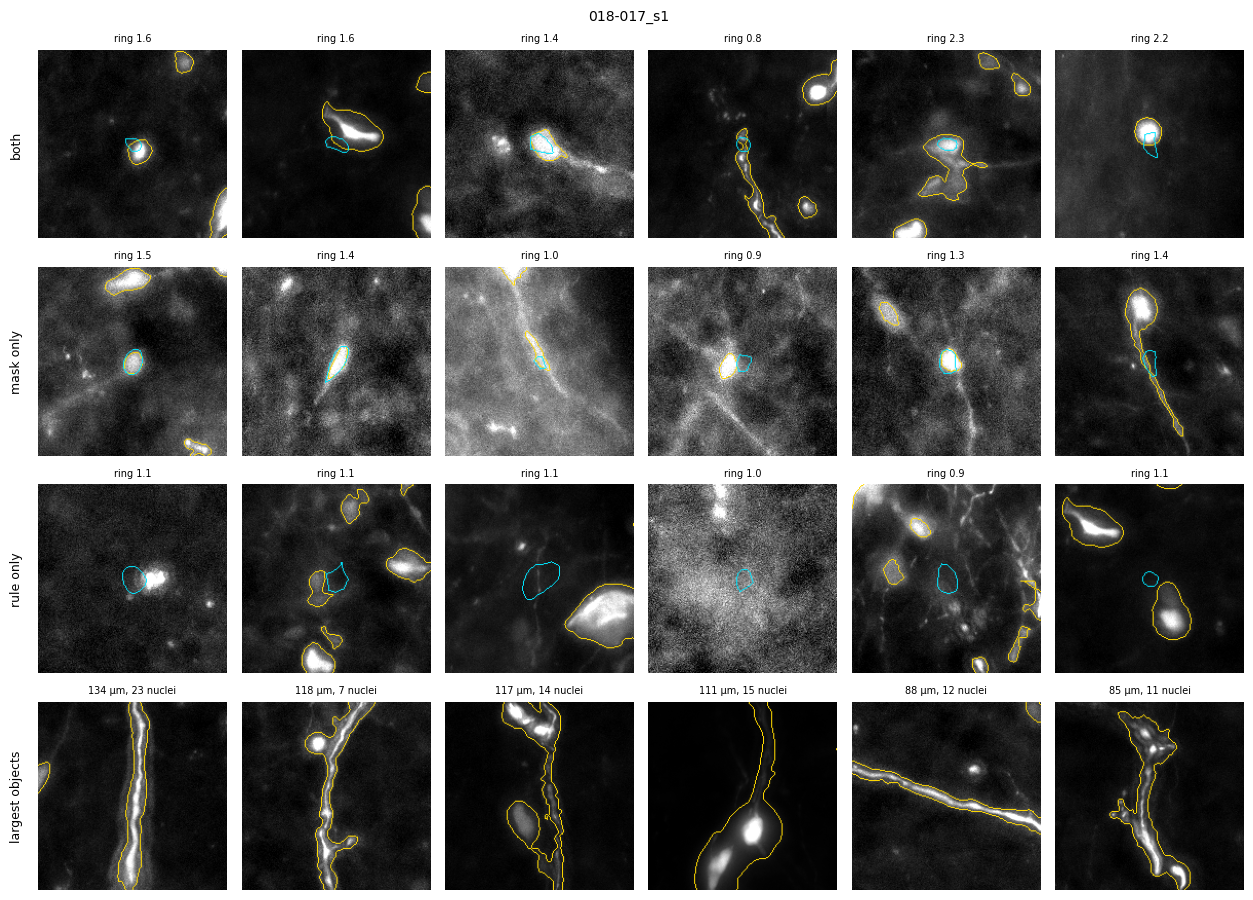

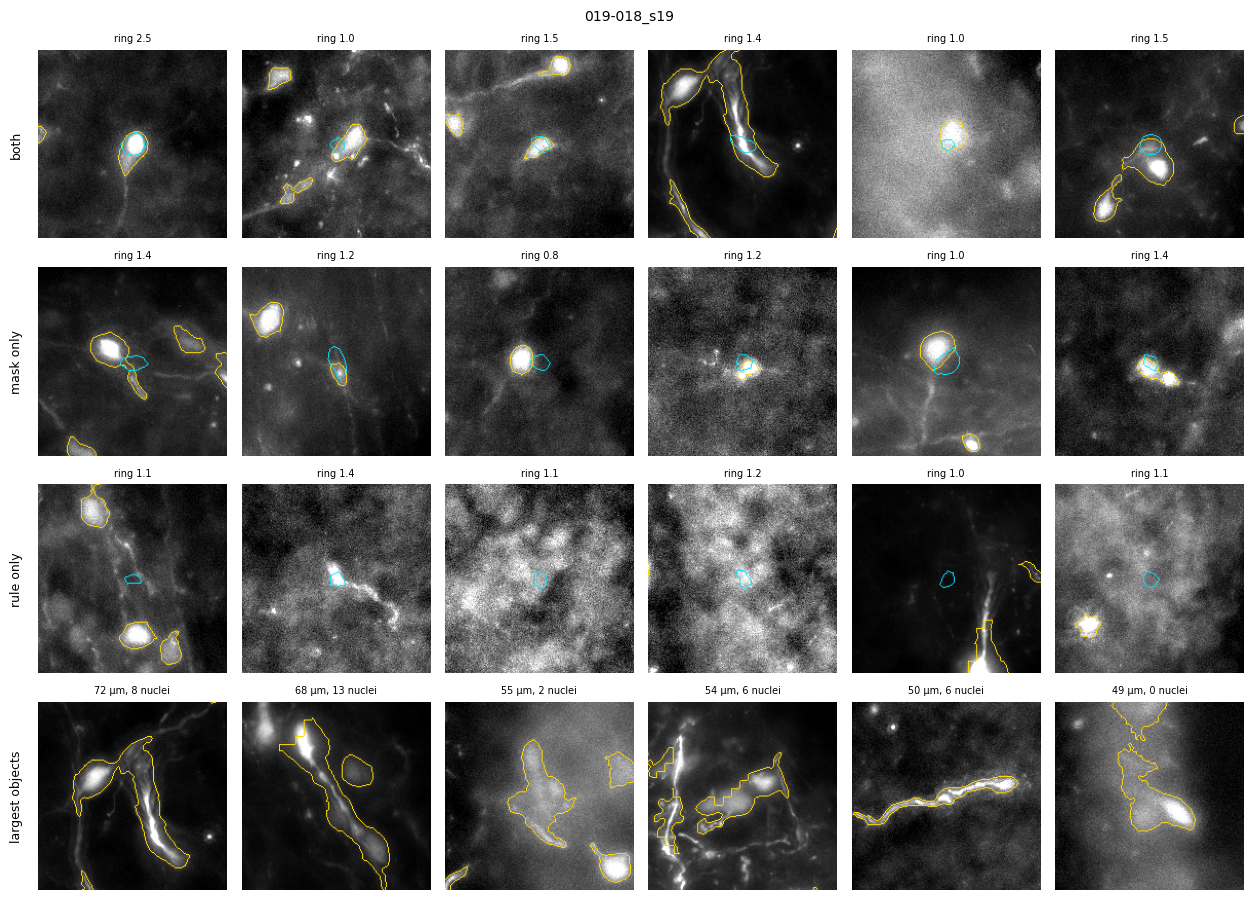

In [9]:
from microscopy_viewer import junction_analysis as ja
from microscopy_viewer import loaders
from skimage.segmentation import find_boundaries
import tifffile

HALF_UM = 30.0
rng = np.random.default_rng(0)


def gallery(name, per_row=6):
    s, c = SUMMARY[name], CELLS[name]
    voxel = s["voxel_um"]
    half = int(HALF_UM / voxel)
    specs = loaders.load_path(Path(s["file"]))
    try:
        names = [str(sp.channel_name or sp.name) for sp in specs]
        i488 = next(i for i, nm in enumerate(names) if "488" in nm)
        whole = (slice(0, s["shape"][0]), slice(0, s["shape"][1]))
        af488 = ja._plane(specs[i488], whole).astype(np.float32)
    finally:
        loaders.release(Path(s["file"]))
    mask = tifffile.imread(CV.OUT / name / f"{MAIN}.tif") > 0
    run = Path(s["run"])
    nuclei = ja.read_labels(run / "labels" / f"{name} nuclei.tif")
    objects = OBJECTS[(name, MAIN)]
    picks = {
        "both": c[c["median + 3 SD"] & c[f"covered {MAIN}"]],
        "mask only": c[c[f"covered {MAIN}"] & ~c["median + 3 SD"] & ~c["ring ≥ 1.5"]],
        "rule only": c[c["median + 3 SD"] & (c[f"cover {MAIN}"].fillna(0) < 0.05)],
        "largest objects": objects.nlargest(per_row, "Skeleton (µm)"),
    }
    fig, axes = plt.subplots(len(picks), per_row, figsize=(2.1 * per_row, 2.3 * len(picks)))
    for row, (title, table) in enumerate(picks.items()):
        chosen = table if len(table) <= per_row or title == "largest objects" else table.iloc[rng.choice(len(table), per_row, replace=False)]
        for col in range(per_row):
            ax = axes[row, col]
            ax.axis("off")
            if col >= len(chosen):
                continue
            item = chosen.iloc[col]
            y, x = int(item["Centroid Y (µm)"] / voxel), int(item["Centroid X (µm)"] / voxel)
            win = (slice(max(y - half, 0), y + half), slice(max(x - half, 0), x + half))
            crop = af488[win]
            lo, hi = np.percentile(crop, (1, 99.5))
            rgb = np.repeat(np.clip((crop - lo) / max(hi - lo, 1), 0, 1)[..., None], 3, axis=2)
            rgb[find_boundaries(mask[win], mode="inner")] = (1.0, 0.85, 0.0)
            if "Label" in item:
                rgb[find_boundaries(nuclei[win] == int(item["Label"]), mode="inner")] = (0.0, 0.9, 1.0)
            ax.imshow(rgb)
            if "ring" in str(item.index.tolist()) and "AF488 ring contrast" in item:
                ax.set_title(f"ring {item['AF488 ring contrast']:.1f}", fontsize=7)
            elif "Skeleton (µm)" in item:
                ax.set_title(f"{item['Skeleton (µm)']:.0f} µm, {int(item['Nuclei touched'])} nuclei", fontsize=7)
        axes[row, 0].text(-0.08, 0.5, title, transform=axes[row, 0].transAxes, rotation=90, va="center", ha="right", fontsize=9)
    fig.suptitle(name.replace("2025_09_26_Asssembloid_", ""), fontsize=10)
    plt.tight_layout()
    plt.show()


for name in [NAMES[0], NAMES[len(NAMES) // 2]]:
    gallery(name)

### What it showed (27 October 2026: 39 slide scans, 1.73 million Cellpose cells)

**The classical AF488 masks agree with ring contrast, not with median + 3 SD.** Median + 3 SD is the odd one out on every measure.

| | cells called (all samples) | κ vs median + 3 SD | κ vs ring ≥ 1.5 | ρ of per-sample counts vs ring ≥ 1.5 |
|---|---|---|---|---|
| Cellpose + median + 3 SD | 93 888 (5.4 %) | — | 0.13 | 0.20 |
| Cellpose + ring ≥ 1.5 | 12 259 (0.7 %) | 0.13 | — | — |
| AF488 mask, k = 3 SD | 65 639 cells covered | 0.37 | 0.23 | 0.77 |
| AF488 mask, k = 5 SD | 26 638 | 0.30 | 0.41 | 0.79 |
| AF488 mask, k = 8 SD | 12 260 | 0.20 | **0.50** | 0.73 |
| AF488 mask, triangle | 16 539 | 0.23 | 0.47 | 0.51 |
| AF488 mask, Otsu | 25 726 | 0.05 | 0.12 | 0.27 |

- **Median + 3 SD calls 3–8× more cells than any AF488 mask**, and its per-sample counts do not rank the samples like anything else (ρ 0.26 or less). The pictures show why: most of the cells only it calls ("rule only") have no visible AF488 at all — they sit in a bright haze, which this rule measures as signal. This is the same overcounting `positivity_metrics` found against the clicks.
- **Ring contrast and the AF488 masks tell the same story.** Each finds most of the other's cells (k = 8: half each way; k = 5 covers 66 % of the ring's positives), the per-sample counts rank alike (ρ 0.73–0.79), and the profile against the line has the same shape: ~1 % positive on the home side, a drop of 3–8 times at the line, 0.1–0.3 % beyond. Median + 3 SD has almost no step and *rises* again past the line (to 5–7 %) — false positives in the other organoid.
- **Otsu fails**: AF488 is one population with a tail, not two groups; its cut lands in a different place on every sample.
- **More of the cell's structure: yes, for the cells that have it.** The typical object is a compact cell body (median 43–50 µm², solidity 0.9 — smaller than a nucleus grown by 3 µm, ~97 µm²), but **60 % of the mask lies outside the nuclei**, the longest tenth of the objects have a centre line over 20–33 µm, and the largest are elongated cells and processes 50–130 µm long that a nucleus + 3 µm cannot describe. About 9 % of the objects touch no Cellpose nucleus at all: labelled bodies whose nucleus Cellpose did not find, or that lie in another plane.
- **The pictures also show a weakness of the nucleus-based call**: a labelled cell body often sits beside the Cellpose nucleus rather than on it ("mask only" row), so a cell can be labelled and not counted, or counted against the wrong nucleus. The AF488 mask does not depend on that match.
- What is not settled here: no clicks were used, so neither side is ground truth. The clicks of `positivity_metrics` (12 samples) are the next check, for the AF488 masks at k = 5 and 8.

**Decision.** Nothing changes in the analysis yet. Suggested next steps, in order: (1) make **ring contrast the default** positivity rule instead of median + 3 SD — the AF488 masks independently confirm it; (2) score the AF488 masks (k = 5 and 8) against the clicks; (3) if they hold, offer *AF488 mask* as a positivity rule and draw the mask's object as the positive cell's outline, which gives the cell's real shape.
